<a href="https://colab.research.google.com/github/munnamia1945/AI_ML_DL_CYS_Projects/blob/main/07-cnn-image-classification/cnn_image_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project 07: CNN Image Classification

### Objective
Build a Convolutional Neural Network (CNN) for multi-class image
classification using TensorFlow and Keras.

### Key Concepts
- Convolutional Neural Networks
- Image augmentation
- Training and validation
- Overfitting prevention
- Early stopping and learning-rate reduction
- Test-set evaluation
- Confusion matrix and classification metrics

### Dataset
CIFAR-10: 60,000 color images across 10 classes.

### Tools
Python, TensorFlow/Keras, NumPy, pandas, Matplotlib, Seaborn,
and Scikit-learn.

### Cell 2 - Import libraries

In [ ]:
import os
import random
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers, models, regularizers

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

sns.set_theme(style="whitegrid")

print("TensorFlow version:", tf.__version__)
print("GPU available:", len(tf.config.list_physical_devices("GPU")) > 0)

TensorFlow version: 2.21.0
GPU available: True


### Cell 3 - Load CIFAR-10 dataset
CIFAR-10 contains 60,000 RGB images of size 32×32, divided into 10 classes. The standard dataset has 50,000 training images and 10,000 test images.

In [ ]:
(x_all, y_all), (x_test, y_test) = keras.datasets.cifar10.load_data()

y_all = y_all.flatten()
y_test = y_test.flatten()

class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

print("Original training data:", x_all.shape)
print("Original training labels:", y_all.shape)
print("Test images:", x_test.shape)
print("Test labels:", y_test.shape)
print("Number of classes:", len(class_names))

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2289s 13us/step
Original training data: (50000, 32, 32, 3)
Original training labels: (50000,)
Test images: (10000, 32, 32, 3)
Test labels: (10000,)
Number of classes: 10


### Cell 4 - Create a validation set

In [ ]:
x_train, x_val, y_train, y_val = train_test_split(
    x_all,
    y_all,
    test_size=0.10,
    random_state=SEED,
    stratify=y_all
)

print("Training images:", x_train.shape[0])
print("Validation images:", x_val.shape[0])
print("Test images:", x_test.shape[0])

Training images: 45000
Validation images: 5000
Test images: 10000


### Cell 5 - Display sample images

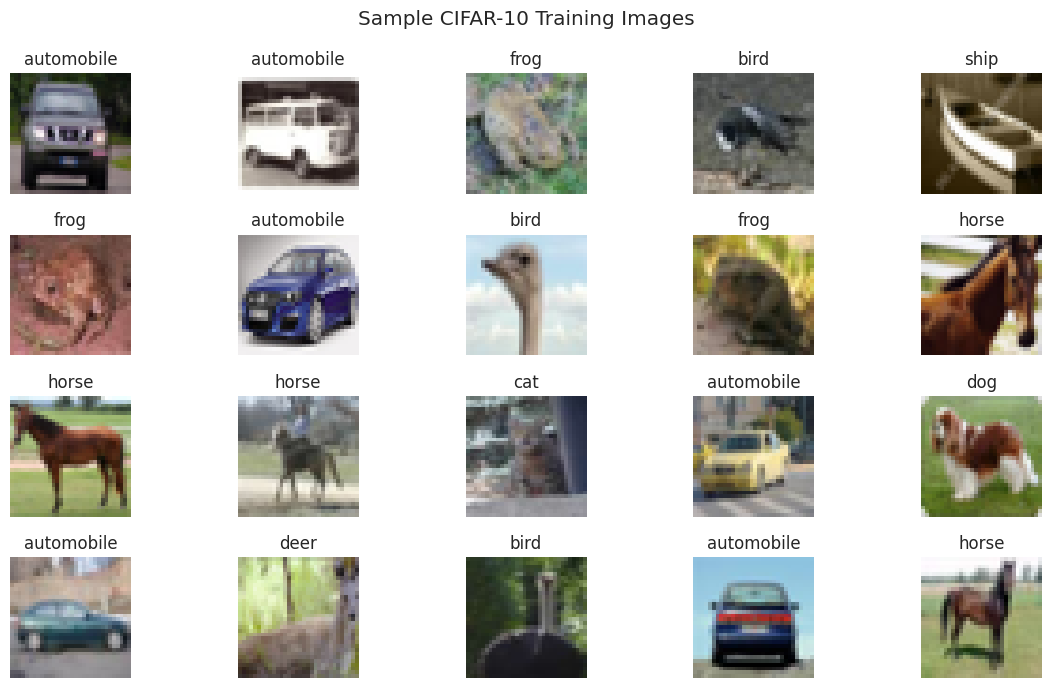

In [ ]:
plt.figure(figsize=(12, 7))

for i in range(20):
    plt.subplot(4, 5, i + 1)
    plt.imshow(x_train[i])
    plt.title(class_names[y_train[i]])
    plt.axis("off")

plt.suptitle("Sample CIFAR-10 Training Images")
plt.tight_layout()
plt.show()

### Cell 6 - Explore class distribution

,Class,Training Samples
0,airplane,4500
1,automobile,4500
2,bird,4500
3,cat,4500
4,deer,4500
5,dog,4500
6,frog,4500
7,horse,4500
8,ship,4500
9,truck,4500


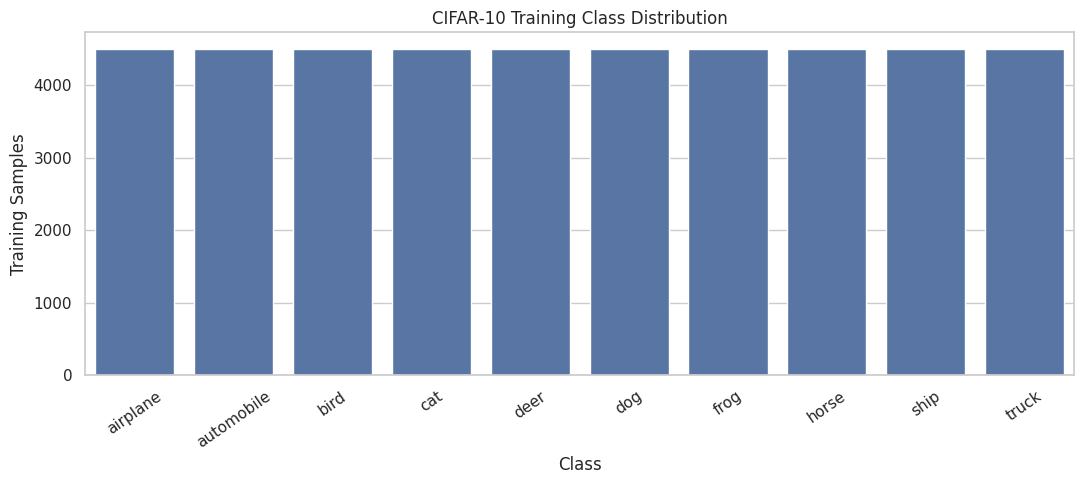

In [ ]:
train_distribution = pd.Series(
    y_train
).value_counts().sort_index()

distribution_df = pd.DataFrame({
    "Class": class_names,
    "Training Samples": [
        int(train_distribution.get(i, 0))
        for i in range(len(class_names))
    ]
})

display(distribution_df)

plt.figure(figsize=(11, 5))
sns.barplot(
    data=distribution_df,
    x="Class",
    y="Training Samples"
)
plt.title("CIFAR-10 Training Class Distribution")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

### Cell 7 - Normalize images
Pixel values originally range from 0 to 255. We will convert them to floating-point values between 0 and 1.

In [ ]:
x_train = x_train.astype("float32") / 255.0
x_val = x_val.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

print("Training pixel range:", x_train.min(), "to", x_train.max())
print("Validation shape:", x_val.shape)
print("Test shape:", x_test.shape)

Training pixel range: 0.0 to 1.0
Validation shape: (5000, 32, 32, 3)
Test shape: (10000, 32, 32, 3)


### Cell 8 - Create image augmentation

In [ ]:
data_augmentation = keras.Sequential(
    [
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.05),
        layers.RandomTranslation(
            height_factor=0.05,
            width_factor=0.05
        )
    ],
    name="data_augmentation"
)

print("Image augmentation pipeline created.")

Image augmentation pipeline created.


### Cell 9 - Visualize augmented images

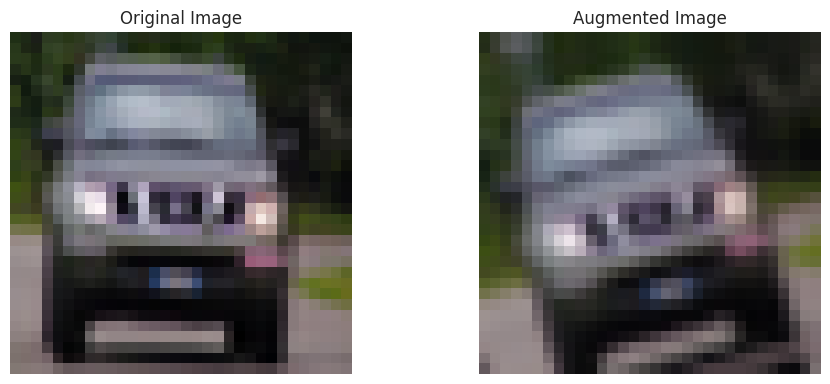

In [ ]:
sample_image = x_train[0:1]

augmented_images = data_augmentation(
    tf.convert_to_tensor(sample_image),
    training=True
).numpy()

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(x_train[0])
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(np.clip(augmented_images[0], 0, 1))
plt.title("Augmented Image")
plt.axis("off")

plt.tight_layout()
plt.show()

### Cell 10 - Build the CNN model

In [ ]:
weight_decay = 1e-4

model = models.Sequential([
    layers.Input(shape=(32, 32, 3)),
    data_augmentation,

    layers.Conv2D(
        32, (3, 3), padding="same",
        activation="relu",
        kernel_regularizer=regularizers.l2(weight_decay)
    ),
    layers.BatchNormalization(),
    layers.Conv2D(
        32, (3, 3), padding="same",
        activation="relu",
        kernel_regularizer=regularizers.l2(weight_decay)
    ),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.20),

    layers.Conv2D(
        64, (3, 3), padding="same",
        activation="relu",
        kernel_regularizer=regularizers.l2(weight_decay)
    ),
    layers.BatchNormalization(),
    layers.Conv2D(
        64, (3, 3), padding="same",
        activation="relu",
        kernel_regularizer=regularizers.l2(weight_decay)
    ),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.30),

    layers.Conv2D(
        128, (3, 3), padding="same",
        activation="relu",
        kernel_regularizer=regularizers.l2(weight_decay)
    ),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.30),

    layers.GlobalAveragePooling2D(),
    layers.Dense(
        128,
        activation="relu",
        kernel_regularizer=regularizers.l2(weight_decay)
    ),
    layers.Dropout(0.40),
    layers.Dense(10, activation="softmax")
])

print("CNN architecture created.")

CNN architecture created.


### Cell 11 - Compile and inspect the model

In [ ]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 158,122 (617.66 KB)

 Trainable params: 157,674 (615.91 KB)

 Non-trainable params: 448 (1.75 KB)

Cell 12 - Configure callbacks

In [ ]:
os.makedirs("project07_outputs", exist_ok=True)

callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    ),

    keras.callbacks.ModelCheckpoint(
        filepath="project07_outputs/best_cnn_model.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

print("Training callbacks configured.")

Training callbacks configured.


### Cell 13 - Train the CNN

In [ ]:
EPOCHS = 20
BATCH_SIZE = 128

history = model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=callbacks,
    verbose=1
)

print("Training completed.")

Epoch 1/20
352/352 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.3065 - loss: 1.9466
Epoch 1: val_loss improved from None to 2.67376, saving model to project07_outputs/best_cnn_model.keras

Epoch 1: finished saving model to project07_outputs/best_cnn_model.keras
352/352 ━━━━━━━━━━━━━━━━━━━━ 17s 26ms/step - accuracy: 0.3748 - loss: 1.7449 - val_accuracy: 0.2640 - val_loss: 2.6738 - learning_rate: 0.0010
Epoch 2/20
351/352 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.4859 - loss: 1.4581
Epoch 2: val_loss improved from 2.67376 to 1.55624, saving model to project07_outputs/best_cnn_model.keras

Epoch 2: finished saving model to project07_outputs/best_cnn_model.keras
352/352 ━━━━━━━━━━━━━━━━━━━━ 8s 24ms/step - accuracy: 0.5071 - loss: 1.4054 - val_accuracy: 0.4908 - val_loss: 1.5562 - learning_rate: 0.0010
Epoch 3/20
351/352 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.5519 - loss: 1.2819
Epoch 3: val_loss improved from 1.55624 to 1.19860, saving model to project07_outputs/best_cnn_

### Cell 14 - Plot training and validation accuracy

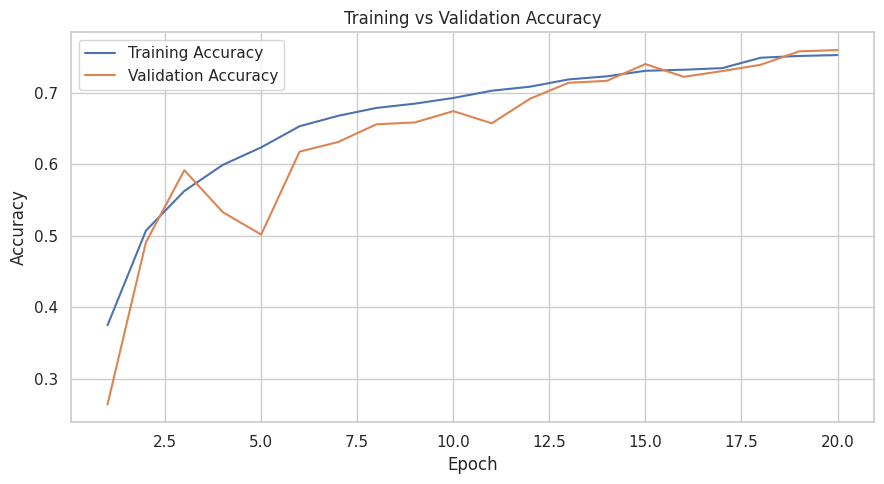

In [ ]:
history_df = pd.DataFrame(history.history)
history_df.index = np.arange(1, len(history_df) + 1)
history_df.index.name = "epoch"

plt.figure(figsize=(9, 5))
plt.plot(history_df.index, history_df["accuracy"], label="Training Accuracy")
plt.plot(history_df.index, history_df["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.tight_layout()
plt.show()

### Cell 15 - Plot training and validation loss

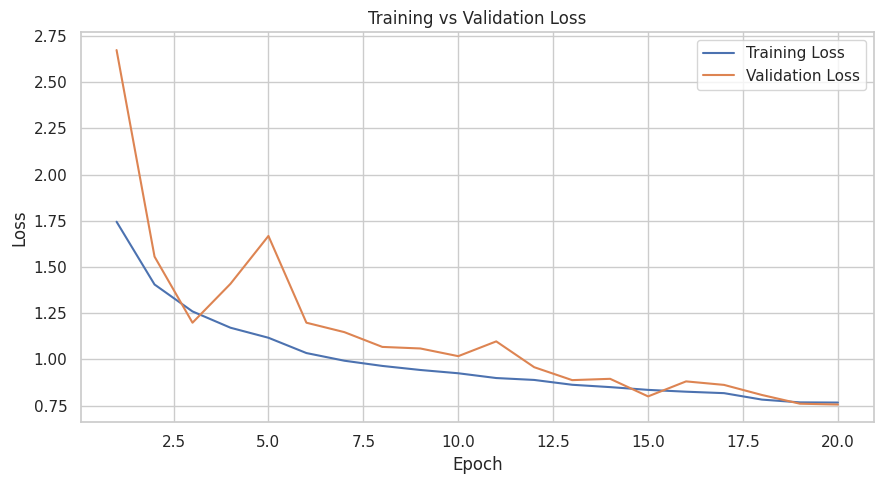

In [ ]:
plt.figure(figsize=(9, 5))
plt.plot(history_df.index, history_df["loss"], label="Training Loss")
plt.plot(history_df.index, history_df["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.tight_layout()
plt.show()

### Cell 16 - Evaluate on the test set

In [ ]:
test_loss, test_accuracy = model.evaluate(
    x_test,
    y_test,
    batch_size=BATCH_SIZE,
    verbose=1
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.7487 - loss: 0.7919
Test Loss: 0.7919
Test Accuracy: 0.7487


### Cell 17 - Generate test predictions and metrics

In [ ]:
y_prob = model.predict(
    x_test,
    batch_size=BATCH_SIZE,
    verbose=1
)

y_pred = np.argmax(y_prob, axis=1)

test_metrics = {
    "Test Loss": float(test_loss),
    "Test Accuracy": accuracy_score(y_test, y_pred),
    "Test Precision (Macro)": precision_score(
        y_test, y_pred, average="macro", zero_division=0
    ),
    "Test Recall (Macro)": recall_score(
        y_test, y_pred, average="macro", zero_division=0
    ),
    "Test F1-Score (Macro)": f1_score(
        y_test, y_pred, average="macro", zero_division=0
    ),
    "Test Precision (Weighted)": precision_score(
        y_test, y_pred, average="weighted", zero_division=0
    ),
    "Test Recall (Weighted)": recall_score(
        y_test, y_pred, average="weighted", zero_division=0
    ),
    "Test F1-Score (Weighted)": f1_score(
        y_test, y_pred, average="weighted", zero_division=0
    )
}

test_metrics_df = pd.DataFrame(
    [test_metrics]
).T.reset_index()

test_metrics_df.columns = ["Metric", "Value"]
display(test_metrics_df.round(4))

79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step


,Metric,Value
0,Test Loss,0.7919
1,Test Accuracy,0.7487
2,Test Precision (Macro),0.7677
3,Test Recall (Macro),0.7487
4,Test F1-Score (Macro),0.7434
5,Test Precision (Weighted),0.7677
6,Test Recall (Weighted),0.7487
7,Test F1-Score (Weighted),0.7434


### Cell 18 - Classification report

In [ ]:
report_text = classification_report(
    y_test,
    y_pred,
    target_names=class_names,
    digits=4,
    zero_division=0
)

print(report_text)

report_dict = classification_report(
    y_test,
    y_pred,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report_dict).T
display(report_df.round(4))

              precision    recall  f1-score   support

    airplane     0.7076    0.8590    0.7760      1000
  automobile     0.9249    0.8990    0.9118      1000
        bird     0.7585    0.5590    0.6436      1000
         cat     0.6756    0.4560    0.5445      1000
        deer     0.6515    0.7740    0.7075      1000
         dog     0.8252    0.5050    0.6266      1000
        frog     0.5571    0.9410    0.6999      1000
       horse     0.8867    0.7120    0.7898      1000
        ship     0.8570    0.8870    0.8717      1000
       truck     0.8326    0.8950    0.8627      1000

    accuracy                         0.7487     10000
   macro avg     0.7677    0.7487    0.7434     10000
weighted avg     0.7677    0.7487    0.7434     10000



,precision,recall,f1-score,support
airplane,0.7076,0.8590,0.7760,1000.0000
automobile,0.9249,0.8990,0.9118,1000.0000
bird,0.7585,0.5590,0.6436,1000.0000
cat,0.6756,0.4560,0.5445,1000.0000
deer,0.6515,0.7740,0.7075,1000.0000
dog,0.8252,0.5050,0.6266,1000.0000
frog,0.5571,0.9410,0.6999,1000.0000
horse,0.8867,0.7120,0.7898,1000.0000
ship,0.8570,0.8870,0.8717,1000.0000
truck,0.8326,0.8950,0.8627,1000.0000


### Cell 19 - Confusion matrix

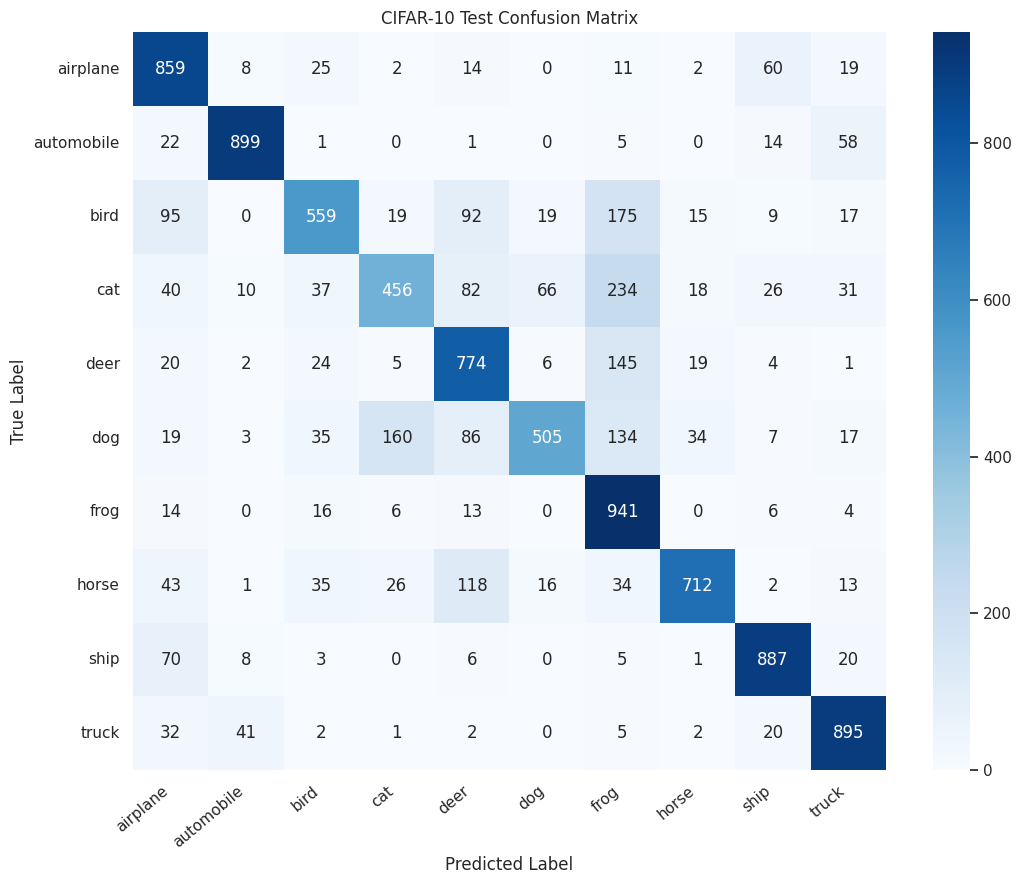

In [ ]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=np.arange(len(class_names))
)

plt.figure(figsize=(11, 9))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("CIFAR-10 Test Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks(rotation=40, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### Cell 20 - Visualize sample predictions

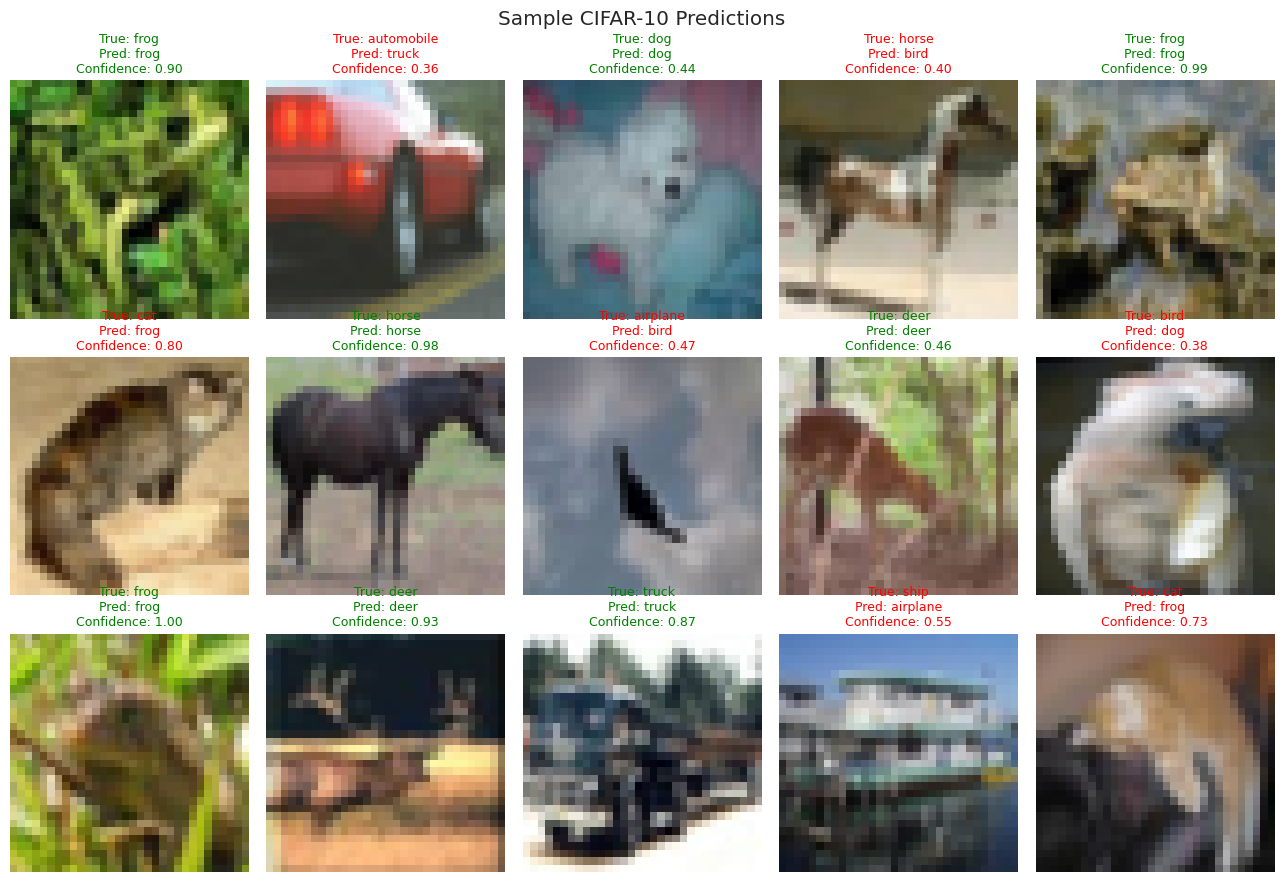

In [ ]:
rng = np.random.default_rng(SEED)
sample_indices = rng.choice(
    len(x_test),
    size=15,
    replace=False
)

plt.figure(figsize=(13, 9))

for plot_idx, sample_idx in enumerate(sample_indices):
    true_label = y_test[sample_idx]
    predicted_label = y_pred[sample_idx]
    confidence = float(np.max(y_prob[sample_idx]))

    plt.subplot(3, 5, plot_idx + 1)
    plt.imshow(x_test[sample_idx])

    color = "green" if true_label == predicted_label else "red"

    plt.title(
        f"True: {class_names[true_label]}\n"
        f"Pred: {class_names[predicted_label]}\n"
        f"Confidence: {confidence:.2f}",
        color=color,
        fontsize=9
    )
    plt.axis("off")

plt.suptitle("Sample CIFAR-10 Predictions")
plt.tight_layout()
plt.show()

### Cell 21 - Analyze overfitting indicators

In [ ]:
best_epoch = int(history_df["val_loss"].idxmin())
best_val_loss = float(history_df["val_loss"].min())

final_epoch = int(history_df.index[-1])
final_train_accuracy = float(history_df.iloc[-1]["accuracy"])
final_val_accuracy = float(history_df.iloc[-1]["val_accuracy"])
accuracy_gap = final_train_accuracy - final_val_accuracy

overfitting_summary = pd.DataFrame({
    "Metric": [
        "Best Epoch (Minimum Validation Loss)",
        "Best Validation Loss",
        "Final Epoch",
        "Final Training Accuracy",
        "Final Validation Accuracy",
        "Final Train-Validation Accuracy Gap"
    ],
    "Value": [
        best_epoch,
        best_val_loss,
        final_epoch,
        final_train_accuracy,
        final_val_accuracy,
        accuracy_gap
    ]
})

display(overfitting_summary.round(4))

print(
    "Interpretation: inspect the accuracy and loss curves together "
    "to assess whether overfitting appears to occur."
)

,Metric,Value
0,Best Epoch (Minimum Validation Loss),20.0000
1,Best Validation Loss,0.7559
2,Final Epoch,20.0000
3,Final Training Accuracy,0.7526
4,Final Validation Accuracy,0.7596
5,Final Train-Validation Accuracy Gap,-0.0070


Interpretation: inspect the accuracy and loss curves together to assess whether overfitting appears to occur.


### Cell 22 - Export metrics and training history

In [ ]:
os.makedirs("project07_outputs", exist_ok=True)

test_metrics_df.to_csv(
    "project07_outputs/cnn_test_metrics.csv",
    index=False
)

history_df.to_csv(
    "project07_outputs/cnn_training_history.csv",
    index=True
)

report_df.to_csv(
    "project07_outputs/cnn_classification_report.csv",
    index=True
)

overfitting_summary.to_csv(
    "project07_outputs/cnn_overfitting_summary.csv",
    index=False
)

print("Exported files:")
print("- cnn_test_metrics.csv")
print("- cnn_training_history.csv")
print("- cnn_classification_report.csv")
print("- cnn_overfitting_summary.csv")

Exported files:
- cnn_test_metrics.csv
- cnn_training_history.csv
- cnn_classification_report.csv
- cnn_overfitting_summary.csv


### Cell 23 - Save the final model

In [ ]:
model.save("project07_outputs/final_cnn_model.keras")

print("Saved model files:")
print("- project07_outputs/best_cnn_model.keras")
print("- project07_outputs/final_cnn_model.keras")

Saved model files:
- project07_outputs/best_cnn_model.keras
- project07_outputs/final_cnn_model.keras


### Cell 24 - Download a ZIP of project outputs

In [ ]:
import shutil

zip_path = shutil.make_archive(
    "project07_outputs",
    "zip",
    root_dir="project07_outputs"
)

print("ZIP created:", zip_path)

# In Google Colab, uncomment these lines to download it:
# from google.colab import files
# files.download(zip_path)

ZIP created: /content/project07_outputs.zip


### Cell 25 - Final summary

In [ ]:
print("=" * 60)
print("PROJECT 07: CNN IMAGE CLASSIFICATION")
print("=" * 60)

print("Dataset: CIFAR-10")
print("Classes:", len(class_names))
print("Training images:", len(x_train))
print("Validation images:", len(x_val))
print("Test images:", len(x_test))
print("Epochs completed:", len(history_df))

print("\nFinal test metrics:")
for metric, value in test_metrics.items():
    print(f"{metric}: {value:.4f}")

print("\nBest validation-loss epoch:", best_epoch)
print(f"Best validation loss: {best_val_loss:.4f}")

print("\nProject completed.")

PROJECT 07: CNN IMAGE CLASSIFICATION
Dataset: CIFAR-10
Classes: 10
Training images: 45000
Validation images: 5000
Test images: 10000
Epochs completed: 20

Final test metrics:
Test Loss: 0.7919
Test Accuracy: 0.7487
Test Precision (Macro): 0.7677
Test Recall (Macro): 0.7487
Test F1-Score (Macro): 0.7434
Test Precision (Weighted): 0.7677
Test Recall (Weighted): 0.7487
Test F1-Score (Weighted): 0.7434

Best validation-loss epoch: 20
Best validation loss: 0.7559

Project completed.


### Cell 26 — Conclusion


#### Conclusion

This project implemented a Convolutional Neural Network (CNN) for
multi-class image classification using the CIFAR-10 dataset.

#### Key Takeaways
- Built a CNN using TensorFlow and Keras.
- Applied image augmentation to improve generalization.
- Used a separate validation set for monitoring model performance.
- Applied dropout, L2 regularization, batch normalization, early stopping,
  and learning-rate reduction.
- Evaluated the model using test accuracy, precision, recall, F1-score,
  classification report, and confusion matrix.
- Compared training and validation curves to inspect overfitting.
- Exported metrics, training history, and saved model files.

#### Limitations
- The experiment uses the CIFAR-10 benchmark dataset.
- Augmentation and regularization do not guarantee that overfitting
  will be eliminated.
- Model performance should be reported using the actual results from
  the completed experiment.
- This model is intended for learning and experimentation.

#### Future Improvements
- Compare the CNN with a baseline model.
- Experiment with different CNN architectures.
- Apply learning-rate schedules and systematic hyperparameter tuning.
- Explore transfer learning with a suitable pretrained model.
- Evaluate per-class performance and misclassified images.